In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)

RANDOM_STATE = 42

print("Semua library berhasil diimpor.")

Semua library berhasil diimpor.


In [2]:
# Nama file dataset
DATASET_PATH = "breast_cancer_wisconsin_diagnostic.csv"

# Membaca dataset
df = pd.read_csv(DATASET_PATH)

print("Dataset berhasil dibaca!")

print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

display(df.head())

Dataset berhasil dibaca!
Jumlah baris: 569
Jumlah kolom: 32


,id,diagnosis,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,...,worst_radius,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
# Informasi dataset
print("Informasi Dataset:")
df.info()

# Memeriksa nilai kosong
print("\nJumlah Missing Values:")
print(df.isnull().sum())

# Distribusi diagnosis
print("\nDistribusi Diagnosis:")
print(df["diagnosis"].value_counts())

# Statistik deskriptif
print("\nStatistik Deskriptif:")
display(df.describe())

Informasi Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   mean_radius              569 non-null    float64
 3   mean_texture             569 non-null    float64
 4   mean_perimeter           569 non-null    float64
 5   mean_area                569 non-null    float64
 6   mean_smoothness          569 non-null    float64
 7   mean_compactness         569 non-null    float64
 8   mean_concavity           569 non-null    float64
 9   mean_concave_points      569 non-null    float64
 10  mean_symmetry            569 non-null    float64
 11  mean_fractal_dimension   569 non-null    float64
 12  se_radius                569 non-null    float64
 13  se_texture               569 non-null    float64
 14  se_perimeter      

,id,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,...,worst_radius,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


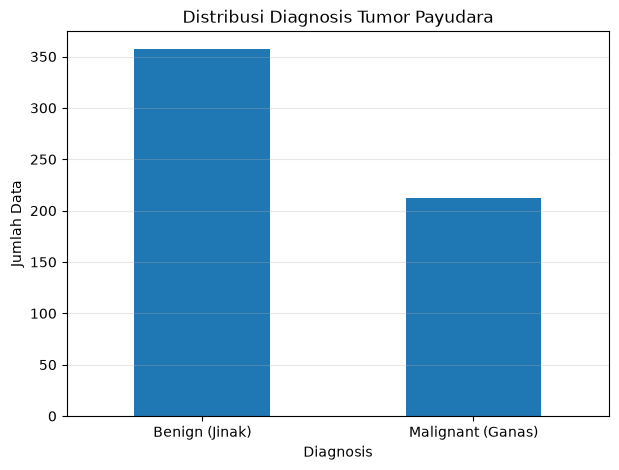

In [4]:
diagnosis_count = df["diagnosis"].value_counts()

plt.figure(figsize=(7, 5))

diagnosis_count.plot(
    kind="bar",
    rot=0
)

plt.title("Distribusi Diagnosis Tumor Payudara")
plt.xlabel("Diagnosis")
plt.ylabel("Jumlah Data")
plt.xticks(
    ticks=[0, 1],
    labels=["Benign (Jinak)", "Malignant (Ganas)"]
)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [5]:
features = [

    # 10 Fitur Mean
    "mean_radius",
    "mean_texture",
    "mean_perimeter",
    "mean_area",
    "mean_smoothness",
    "mean_compactness",
    "mean_concavity",
    "mean_concave_points",
    "mean_symmetry",
    "mean_fractal_dimension",

    # 10 Fitur Standard Error (SE)
    "se_radius",
    "se_texture",
    "se_perimeter",
    "se_area",
    "se_smoothness",
    "se_compactness",
    "se_concavity",
    "se_concave_points",
    "se_symmetry",
    "se_fractal_dimension",

    # 10 Fitur Worst
    "worst_radius",
    "worst_texture",
    "worst_perimeter",
    "worst_area",
    "worst_smoothness",
    "worst_compactness",
    "worst_concavity",
    "worst_concave_points",
    "worst_symmetry",
    "worst_fractal_dimension"
]

print("Jumlah fitur:", len(features))

print("\nDaftar fitur yang digunakan:")

for i, feature in enumerate(features, start=1):
    print(f"{i}. {feature}")

Jumlah fitur: 30

Daftar fitur yang digunakan:
1. mean_radius
2. mean_texture
3. mean_perimeter
4. mean_area
5. mean_smoothness
6. mean_compactness
7. mean_concavity
8. mean_concave_points
9. mean_symmetry
10. mean_fractal_dimension
11. se_radius
12. se_texture
13. se_perimeter
14. se_area
15. se_smoothness
16. se_compactness
17. se_concavity
18. se_concave_points
19. se_symmetry
20. se_fractal_dimension
21. worst_radius
22. worst_texture
23. worst_perimeter
24. worst_area
25. worst_smoothness
26. worst_compactness
27. worst_concavity
28. worst_concave_points
29. worst_symmetry
30. worst_fractal_dimension


In [6]:
# Mengambil 30 fitur sebagai variabel X
X = df[features].copy()

# Mengambil diagnosis sebagai target y
y = df["diagnosis"].map({
    "B": 0,
    "M": 1
})

# Memastikan tidak ada label yang gagal dikonversi
if y.isnull().any():
    raise ValueError("Ditemukan label diagnosis yang tidak dikenal.")

y = y.astype(int)

print("Bentuk X:", X.shape)
print("Bentuk y:", y.shape)

print("\nDistribusi target:")
print(y.value_counts())

print("\nContoh fitur:")
display(X.head())

Bentuk X: (569, 30)
Bentuk y: (569,)

Distribusi target:
diagnosis
0    357
1    212
Name: count, dtype: int64

Contoh fitur:


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,mean_fractal_dimension,...,worst_radius,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [7]:
# Mengubah seluruh fitur menjadi numerik
X = X.apply(pd.to_numeric, errors="coerce")

# Menghilangkan nilai tak hingga
X = X.replace([np.inf, -np.inf], np.nan)

# Menggabungkan fitur dan target untuk pembersihan baris
data = X.copy()
data["diagnosis"] = y

jumlah_awal = len(data)

data = data.dropna()

jumlah_akhir = len(data)

# Memisahkan kembali X dan y
X = data[features]
y = data["diagnosis"].astype(int)

print("Jumlah data awal:", jumlah_awal)
print("Jumlah data setelah dibersihkan:", jumlah_akhir)
print("Jumlah data yang dihapus:", jumlah_awal - jumlah_akhir)

print("\nMissing value setelah pembersihan:")
print(X.isnull().sum().sum())

Jumlah data awal: 569
Jumlah data setelah dibersihkan: 569
Jumlah data yang dihapus: 0

Missing value setelah pembersihan:
0


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

print("\nDistribusi data training:")
print(y_train.value_counts())

print("\nDistribusi data testing:")
print(y_test.value_counts())

Jumlah data training: 455
Jumlah data testing: 114

Distribusi data training:
diagnosis
0    285
1    170
Name: count, dtype: int64

Distribusi data testing:
diagnosis
0    72
1    42
Name: count, dtype: int64


In [9]:
logistic_model = Pipeline([

    ("scaler", StandardScaler()),

    ("model", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))

])

print("Model Logistic Regression berhasil dibuat.")

Model Logistic Regression berhasil dibuat.


In [10]:
logistic_model.fit(
    X_train,
    y_train
)

print("Pelatihan Logistic Regression selesai!")

Pelatihan Logistic Regression selesai!


In [11]:
# Prediksi kelas
y_pred_lr = logistic_model.predict(X_test)

# Prediksi probabilitas kelas ganas
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

print("Hasil Prediksi Logistic Regression:")
print(y_pred_lr[:10])

print("\nProbabilitas kelas ganas:")
print(y_prob_lr[:10])

Hasil Prediksi Logistic Regression:
[0 1 0 1 1 0 1 0 0 0]

Probabilitas kelas ganas:
[3.64568116e-04 9.99999989e-01 4.25679471e-02 5.76187322e-01
 5.09155489e-01 6.16001620e-04 7.61534086e-01 1.01217174e-03
 5.68725516e-04 1.07675795e-02]


In [12]:
accuracy_lr = accuracy_score(y_test, y_pred_lr)

precision_lr = precision_score(
    y_test,
    y_pred_lr,
    zero_division=0
)

recall_lr = recall_score(
    y_test,
    y_pred_lr,
    zero_division=0
)

f1_lr = f1_score(
    y_test,
    y_pred_lr,
    zero_division=0
)

roc_auc_lr = roc_auc_score(
    y_test,
    y_prob_lr
)

print("HASIL EVALUASI LOGISTIC REGRESSION")
print("----------------------------------")

print(f"Accuracy  : {accuracy_lr:.4f}")
print(f"Precision : {precision_lr:.4f}")
print(f"Recall    : {recall_lr:.4f}")
print(f"F1-Score  : {f1_lr:.4f}")
print(f"ROC-AUC   : {roc_auc_lr:.4f}")

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_lr,
    target_names=[
        "Benign (Jinak)",
        "Malignant (Ganas)"
    ],
    zero_division=0
))

HASIL EVALUASI LOGISTIC REGRESSION
----------------------------------
Accuracy  : 0.9649
Precision : 0.9750
Recall    : 0.9286
F1-Score  : 0.9512
ROC-AUC   : 0.9960

Classification Report:
                   precision    recall  f1-score   support

   Benign (Jinak)       0.96      0.99      0.97        72
Malignant (Ganas)       0.97      0.93      0.95        42

         accuracy                           0.96       114
        macro avg       0.97      0.96      0.96       114
     weighted avg       0.97      0.96      0.96       114



In [13]:
decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

print("Model Decision Tree berhasil dibuat.")

Model Decision Tree berhasil dibuat.


In [14]:
decision_tree_model.fit(
    X_train,
    y_train
)

print("Pelatihan Decision Tree selesai!")

Pelatihan Decision Tree selesai!


In [15]:
# Prediksi kelas
y_pred_dt = decision_tree_model.predict(X_test)

# Prediksi probabilitas kelas ganas
y_prob_dt = decision_tree_model.predict_proba(X_test)[:, 1]

print("Hasil Prediksi Decision Tree:")
print(y_pred_dt[:10])

print("\nProbabilitas kelas ganas:")
print(y_prob_dt[:10])

Hasil Prediksi Decision Tree:
[0 1 1 1 0 0 1 0 0 0]

Probabilitas kelas ganas:
[0. 1. 1. 1. 0. 0. 1. 0. 0. 0.]


In [16]:
accuracy_dt = accuracy_score(y_test, y_pred_dt)

precision_dt = precision_score(
    y_test,
    y_pred_dt,
    zero_division=0
)

recall_dt = recall_score(
    y_test,
    y_pred_dt,
    zero_division=0
)

f1_dt = f1_score(
    y_test,
    y_pred_dt,
    zero_division=0
)

roc_auc_dt = roc_auc_score(
    y_test,
    y_prob_dt
)

print("HASIL EVALUASI DECISION TREE")
print("----------------------------")

print(f"Accuracy  : {accuracy_dt:.4f}")
print(f"Precision : {precision_dt:.4f}")
print(f"Recall    : {recall_dt:.4f}")
print(f"F1-Score  : {f1_dt:.4f}")
print(f"ROC-AUC   : {roc_auc_dt:.4f}")

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_dt,
    target_names=[
        "Benign (Jinak)",
        "Malignant (Ganas)"
    ],
    zero_division=0
))

HASIL EVALUASI DECISION TREE
----------------------------
Accuracy  : 0.9298
Precision : 0.9048
Recall    : 0.9048
F1-Score  : 0.9048
ROC-AUC   : 0.9246

Classification Report:
                   precision    recall  f1-score   support

   Benign (Jinak)       0.94      0.94      0.94        72
Malignant (Ganas)       0.90      0.90      0.90        42

         accuracy                           0.93       114
        macro avg       0.92      0.92      0.92       114
     weighted avg       0.93      0.93      0.93       114



In [17]:
comparison = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Decision Tree"
    ],

    "Accuracy": [
        accuracy_lr,
        accuracy_dt
    ],

    "Precision": [
        precision_lr,
        precision_dt
    ],

    "Recall": [
        recall_lr,
        recall_dt
    ],

    "F1-Score": [
        f1_lr,
        f1_dt
    ],

    "ROC-AUC": [
        roc_auc_lr,
        roc_auc_dt
    ]

})

display(
    comparison.round(4)
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.9649,0.9750,0.9286,0.9512,0.9960
1,Decision Tree,0.9298,0.9048,0.9048,0.9048,0.9246


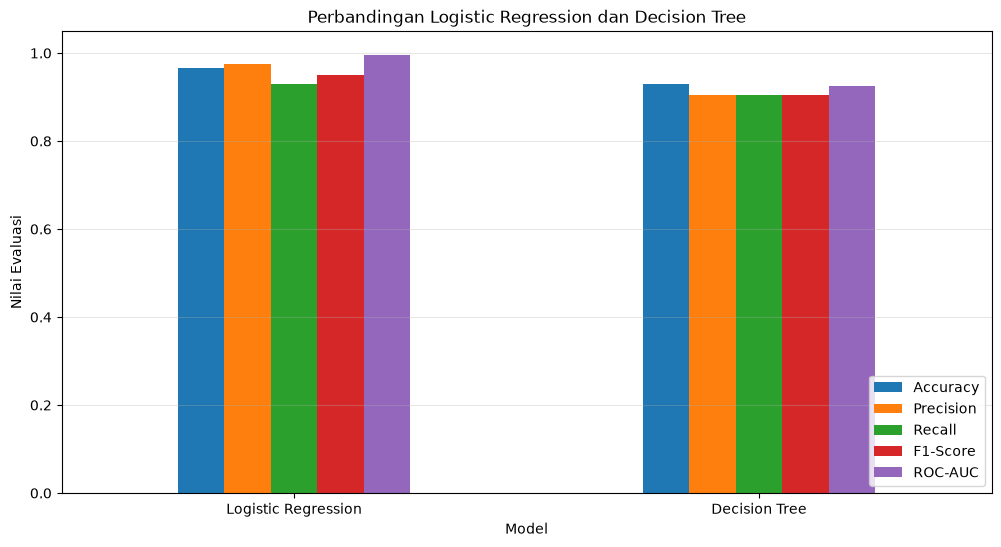

In [18]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

comparison_plot = comparison.set_index("Model")[metrics]

comparison_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Perbandingan Logistic Regression dan Decision Tree")
plt.ylabel("Nilai Evaluasi")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)

plt.show()

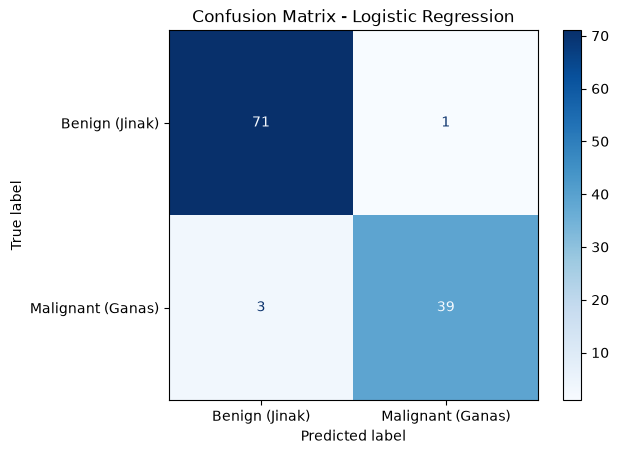

In [19]:
cm_lr = confusion_matrix(
    y_test,
    y_pred_lr,
    labels=[0, 1]
)

display_lr = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=[
        "Benign (Jinak)",
        "Malignant (Ganas)"
    ]
)

display_lr.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix - Logistic Regression")
plt.show()

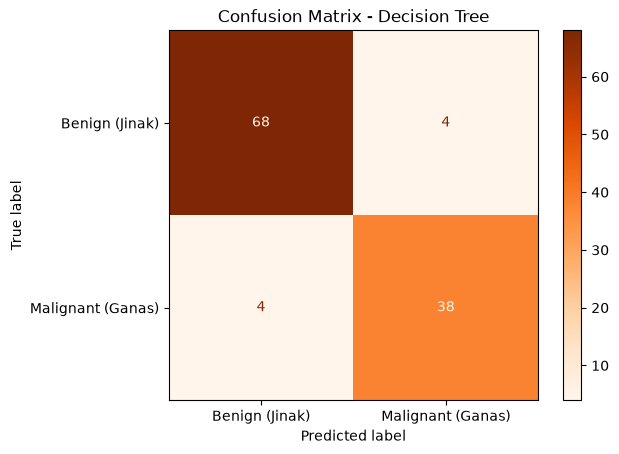

In [20]:
cm_dt = confusion_matrix(
    y_test,
    y_pred_dt,
    labels=[0, 1]
)

display_dt = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=[
        "Benign (Jinak)",
        "Malignant (Ganas)"
    ]
)

display_dt.plot(cmap="Oranges", values_format="d")

plt.title("Confusion Matrix - Decision Tree")
plt.show()

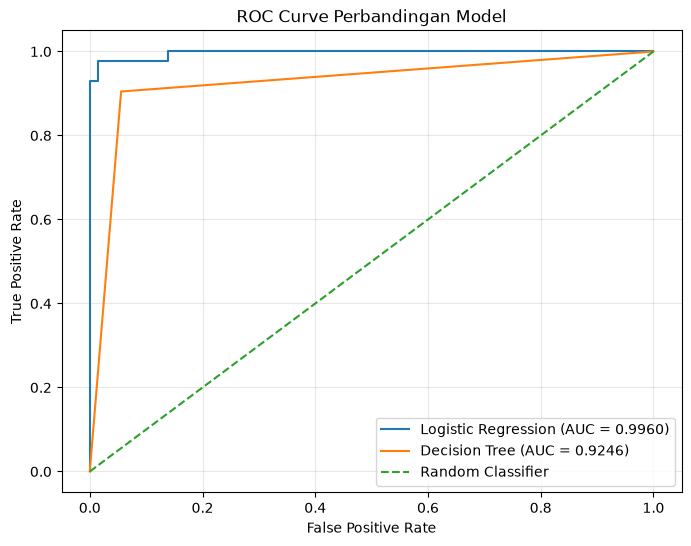

In [21]:
fpr_lr, tpr_lr, _ = roc_curve(
    y_test,
    y_prob_lr
)

fpr_dt, tpr_dt, _ = roc_curve(
    y_test,
    y_prob_dt
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f"Logistic Regression (AUC = {roc_auc_lr:.4f})"
)

plt.plot(
    fpr_dt,
    tpr_dt,
    label=f"Decision Tree (AUC = {roc_auc_dt:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve Perbandingan Model")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [22]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model
}

cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    cv_results.append({

        "Model": name,
        "Mean Accuracy": scores.mean(),
        "Standard Deviation": scores.std()

    })

    print("\nModel:", name)
    print("Nilai setiap fold:", scores)
    print("Rata-rata:", scores.mean())
    print("Standar deviasi:", scores.std())

cv_comparison = pd.DataFrame(cv_results)

display(cv_comparison.round(4))


Model: Logistic Regression
Nilai setiap fold: [0.95604396 0.96703297 1.         0.97802198 0.96703297]
Rata-rata: 0.9736263736263737
Standar deviasi: 0.014906219743132443

Model: Decision Tree
Nilai setiap fold: [0.89010989 0.96703297 0.89010989 0.91208791 0.95604396]
Rata-rata: 0.923076923076923
Standar deviasi: 0.032598674668552395


,Model,Mean Accuracy,Standard Deviation
0,Logistic Regression,0.9736,0.0149
1,Decision Tree,0.9231,0.0326


In [23]:
coefficients = logistic_model.named_steps["model"].coef_[0]

feature_importance_lr = pd.DataFrame({

    "Fitur": features,
    "Koefisien": coefficients,
    "Nilai Absolut": np.abs(coefficients)

})

feature_importance_lr = feature_importance_lr.sort_values(
    by="Nilai Absolut",
    ascending=False
)

display(feature_importance_lr.head(10))

,Fitur,Koefisien,Nilai Absolut
21,worst_texture,1.434093,1.434093
10,se_radius,1.233325,1.233325
28,worst_symmetry,1.061264,1.061264
7,mean_concave_points,0.952813,0.952813
26,worst_concavity,0.911406,0.911406
13,se_area,0.909029,0.909029
15,se_compactness,-0.906925,0.906925
23,worst_area,0.900477,0.900477
20,worst_radius,0.896968,0.896968
6,mean_concavity,0.782298,0.782298


In [24]:
feature_importance_dt = pd.DataFrame({

    "Fitur": features,
    "Importance": decision_tree_model.feature_importances_

})

feature_importance_dt = feature_importance_dt.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance_dt.head(10))

,Fitur,Importance
22,worst_perimeter,0.727477
27,worst_concave_points,0.078970
24,worst_smoothness,0.040833
1,mean_texture,0.037871
21,worst_texture,0.022545
3,mean_area,0.022452
20,worst_radius,0.017530
23,worst_area,0.015606
7,mean_concave_points,0.013416
16,se_concavity,0.007043


In [25]:
# Membuat folder penyimpanan
os.makedirs("hasil_training", exist_ok=True)

# Menyimpan Logistic Regression
joblib.dump(
    logistic_model,
    "hasil_training/logistic_regression.joblib"
)

# Menyimpan Decision Tree
joblib.dump(
    decision_tree_model,
    "hasil_training/decision_tree.joblib"
)

# Menyimpan metadata fitur
metadata = {

    "features": features,

    "target": "diagnosis",

    "class_mapping": {
        "B": 0,
        "M": 1
    },

    "class_names": {
        "0": "Benign (Jinak)",
        "1": "Malignant (Ganas)"
    },

    "positive_class": 1

}

with open(
    "hasil_training/metadata.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        metadata,
        file,
        indent=4,
        ensure_ascii=False
    )

print("Model berhasil disimpan!")

Model berhasil disimpan!


In [26]:
# Menyimpan perbandingan model
comparison.to_csv(
    "hasil_training/perbandingan_model.csv",
    index=False
)

# Menyimpan hasil cross validation
cv_comparison.to_csv(
    "hasil_training/cross_validation.csv",
    index=False
)

# Menyimpan analisis fitur
feature_importance_lr.to_csv(
    "hasil_training/feature_importance_logistic.csv",
    index=False
)

feature_importance_dt.to_csv(
    "hasil_training/feature_importance_decision_tree.csv",
    index=False
)

print("Seluruh hasil evaluasi berhasil disimpan.")

Seluruh hasil evaluasi berhasil disimpan.


In [27]:
print("DAFTAR FILE HASIL TRAINING")
print("--------------------------")

for file in os.listdir("hasil_training"):
    print(file)

DAFTAR FILE HASIL TRAINING
--------------------------
cross_validation.csv
decision_tree.joblib
feature_importance_decision_tree.csv
feature_importance_logistic.csv
logistic_regression.joblib
metadata.json
perbandingan_model.csv
